# 02. Python visualization: đọc metrics và giải thích WHY

Chạy `01_scala_graph_benchmark.ipynb` trước.
Notebook này chỉ đọc kết quả Scala đã hoàn tất; không tạo SparkSession, biên dịch Scala hay chạy benchmark.
Luồng phân tích: correctness → metrics → runtime → memory/GC → shuffle/skew → iteration → DAG/plan → WHY.
Mỗi biểu đồ gắn với đúng input, phiên bản và cấu hình được lưu trong run manifest.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/download_aml.py').exists())
LATEST = ROOT / 'reports/architecture/latest_run.json'
latest = json.loads(LATEST.read_text())
assert latest.get('workflow') == 'native-scala-notebook', 'Chạy 01_scala_graph_benchmark.ipynb trước.'
RUN_DIR = ROOT / latest['run_dir']
assert (RUN_DIR / 'SUCCESS').exists(), 'Benchmark chưa hoàn tất.'
EVENT_DIR = RUN_DIR / 'events'
REPORT = RUN_DIR / 'analysis'
REPORT.mkdir(exist_ok=True)
manifest = json.loads((RUN_DIR / 'input_manifest.json').read_text())
run_config = dict(line.split('=',1) for line in (RUN_DIR/'environment.txt').read_text().splitlines() if '=' in line)
ITERATIONS, PARTITIONS = int(run_config['iterations']), int(run_config['partitions'])
REPEATS, WARMUPS, MASTER = int(run_config['repeats']), int(run_config['warmups']), run_config['master']
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.2})
pd.set_option('display.max_columns',30)
pd.set_option('display.float_format',lambda x:f'{x:,.3f}')
print('Selected run:',RUN_DIR)
display(pd.Series({**run_config,'currency':manifest['currency']}).to_frame('value'))


Selected run: /home/tuanta/graphX/reports/architecture/runs/scala_1792035232036


,value
spark,3.5.7
scala,2.12.18
java,17.0.20.1
master,local[2]
vertices,54019
edges,50000
partitions,4
iterations,5
repeats,3
warmups,1


## 1. Đúng trước khi nhanh

Reference được tính một lần bằng vòng lặp Scala trên driver, độc lập với GraphX và GraphFrames.
Mỗi run so incoming amount tại **từng vertex**, không chỉ so tổng tiền của cả graph.
PageRank được so tại từng vertex sau đúng số iteration, đồng thời kiểm tra tổng rank bằng 1.
Sai số scaled là `abs(actual - expected) / max(1, abs(expected))`, ngưỡng 1e-9; bảng cũng ghi sai số tuyệt đối.
Vertex không nhận tiền có incoming sum bằng 0, kể cả khi API không trả một dòng cho vertex đó.

In [2]:
schedule = pd.read_csv(RUN_DIR / 'schedule.csv')
correctness = pd.read_csv(RUN_DIR / 'correctness.csv').merge(schedule, on='run', validate='many_to_one')
assert correctness.passed.all()
assert len(correctness) == 2 * len(schedule)
assert not schedule.run.duplicated().any()
display(correctness.groupby(['framework', 'kind']).agg(runs=('passed','size'), max_abs_error=('max_abs_error','max'), max_scaled_error=('max_scaled_error','max')))
print('Tất cả input/partition/AQE/repeat có kết quả số học tương đương.')

runs  max_abs_error  max_scaled_error
framework   kind                                           
GraphFrames incoming    16          0.000             0.000
            pagerank    16          0.000             0.000
GraphX      incoming    16          0.000             0.000
            pagerank    16          0.000             0.000

Tất cả input/partition/AQE/repeat có kết quả số học tương đương.


## 2. Spark metrics từ event log

[Monitoring của Spark](https://spark.apache.org/docs/3.5.7/monitoring.html) mô tả event log, task metrics và History Server.
Chỉ task thực sự chạy được tính; stage đã cache và chỉ được JobStart tham chiếu lại không bị đếm như stage đã chạy thêm.
Shuffle read gồm local và remote bytes; executor CPU dùng nanosecond và được đổi sang millisecond.
Executor runtime, GC và CPU là tổng theo task, không phải wall time.
Trong local mode, các task cùng JVM nên GC task metrics có thể chồng lấp; `jvm_gc_ms` là delta GC của JVM, không cộng theo task.
`executor_deserialize_ms` đo deserialize task/closure, `result_serialize_ms` đo serialize task result; chúng **không phải** toàn bộ chi phí decode/encode từng record hoặc shuffle serialization.
Peak execution memory là max của từng task, không phải peak heap toàn ứng dụng.
Task skew được tính theo stage bằng max duration / median duration; không so trực tiếp task từ các stage làm việc khác nhau.

In [3]:
jobs, stage_rows, task_rows, sql_events = [], [], [], []
stage_group = {}
execution_group = {}
for path in sorted(EVENT_DIR.iterdir()):
    if path.name.startswith('.') or path.suffix == '.crc':
        continue
    with path.open() as stream:
        for line in stream:
            event = json.loads(line)
            kind = event.get('Event', '')
            if kind == 'SparkListenerJobStart':
                props = event.get('Properties') or {}
                group = props.get('spark.jobGroup.id', '')
                for stage_id in event['Stage IDs']:
                    stage_group[stage_id] = group
                jobs.append({'group': group, 'job_id': event['Job ID']})
                if props.get('spark.sql.execution.id'):
                    execution_group[int(props['spark.sql.execution.id'])] = group
            elif kind == 'SparkListenerStageSubmitted':
                info = event['Stage Info']
                stage_rows.append({'group': stage_group.get(info['Stage ID'], ''), 'stage_id': info['Stage ID'],
                                   'attempt': info['Stage Attempt ID'], 'name': info['Stage Name'],
                                   'parents': info['Parent IDs'], 'planned_tasks': info['Number of Tasks']})
            elif kind == 'SparkListenerTaskEnd':
                m = event.get('Task Metrics', {})
                info = event['Task Info']
                read = m.get('Shuffle Read Metrics', {})
                write = m.get('Shuffle Write Metrics', {})
                task_rows.append({
                    'group': stage_group.get(event['Stage ID'], ''), 'stage_id': event['Stage ID'],
                    'attempt': event['Stage Attempt ID'], 'task_id': info['Task ID'], 'partition_id': info['Index'],
                    'successful': info.get('Successful', event['Task End Reason'].get('Reason') == 'Success'),
                    'task_duration_ms': info['Finish Time'] - info['Launch Time'],
                    'executor_runtime_ms': m.get('Executor Run Time', 0),
                    'executor_cpu_ms': m.get('Executor CPU Time', 0) / 1e6,
                    'task_gc_ms': m.get('JVM GC Time', 0),
                    'executor_deserialize_ms': m.get('Executor Deserialize Time', 0),
                    'executor_deserialize_cpu_ms': m.get('Executor Deserialize CPU Time', 0) / 1e6,
                    'result_serialize_ms': m.get('Result Serialization Time', 0),
                    'shuffle_read_bytes': read.get('Local Bytes Read', 0) + read.get('Remote Bytes Read', 0),
                    'shuffle_write_bytes': write.get('Shuffle Bytes Written', 0),
                    'memory_spill_bytes': m.get('Memory Bytes Spilled', 0),
                    'disk_spill_bytes': m.get('Disk Bytes Spilled', 0),
                    'peak_task_execution_memory_bytes': m.get('Peak Execution Memory', 0),
                })
            elif kind.endswith(('SparkListenerSQLExecutionStart', 'SparkListenerSQLAdaptiveExecutionUpdate')):
                sql_events.append({'execution_id': event['executionId'], 'event': kind.split('.')[-1],
                                   'description': event.get('description', ''), 'plan': event.get('physicalPlanDescription', '')})

tasks = pd.DataFrame(task_rows)
stages = pd.DataFrame(stage_rows)
job_table = pd.DataFrame(jobs)
assert tasks.successful.all(), 'Có task thất bại; cần kiểm tra spark.log trước khi dùng benchmark.'
for table in [tasks, stages, job_table]:
    parts = table['group'].str.split('|', expand=True, regex=False).reindex(columns=range(3))
    table['run'], table['phase'] = parts[0], parts[1]
    table['iteration'] = pd.to_numeric(parts[2], errors='coerce').fillna(0).astype(int)
    table.drop(columns='group', inplace=True)
keys = ['run', 'phase', 'iteration']
metric_names = [c for c in tasks.columns if c.endswith(('_ms', '_bytes')) and c not in ['task_duration_ms', 'peak_task_execution_memory_bytes']]
task_summary = tasks.groupby(keys)[metric_names].sum()
task_summary['tasks'] = tasks.groupby(keys).size()
task_summary['peak_task_execution_memory_bytes'] = tasks.groupby(keys).peak_task_execution_memory_bytes.max()
metrics = pd.read_csv(RUN_DIR / 'phase_timings.csv').merge(task_summary.reset_index(), on=keys, how='left', validate='one_to_one')
metrics = metrics.merge(stages.groupby(keys).stage_id.nunique().rename('stages').reset_index(), on=keys, how='left')
metrics = metrics.merge(job_table.groupby(keys).job_id.nunique().rename('jobs').reset_index(), on=keys, how='left')
metrics = metrics.merge(schedule, on='run', validate='many_to_one')
assert metrics.tasks.notna().all(), 'Một pha đo không có task metrics: kiểm tra mapping job group.'
measured = metrics.loc[~metrics.warmup].copy()
measured['config'] = measured.framework + '/' + measured.strategy + measured.aqe.map({False:'/AQE-OFF',True:'/AQE-ON'})

stage_skew = tasks.groupby(['run', 'phase', 'iteration', 'stage_id', 'attempt']).task_duration_ms.agg(tasks='size', median_ms='median', max_ms='max', p95_ms=lambda s: s.quantile(.95)).reset_index()
stage_skew['max_over_median'] = stage_skew.max_ms / stage_skew.median_ms.replace(0, np.nan)
stage_skew = stage_skew.merge(schedule, on='run', validate='many_to_one')
for name, table in [('metrics',metrics), ('tasks',tasks), ('stages',stages), ('stage_skew',stage_skew), ('correctness',correctness)]:
    table.to_csv(REPORT / f'{name}.csv', index=False)
for row in sql_events:
    row['group'] = execution_group.get(row['execution_id'], '')
(REPORT / 'sql_plans.json').write_text(json.dumps(sql_events, ensure_ascii=False, indent=2))
print(f'{len(measured)} pha được đo, {len(tasks):,} task trong toàn app; warmup được giữ trong raw metrics nhưng loại khỏi biểu đồ.')

192 pha được đo, 6,476 task trong toàn app; warmup được giữ trong raw metrics nhưng loại khỏi biểu đồ.


## 3. Bảng kết quả: bắt đầu từ runtime, rồi mở xuống tầng thấp

Bảng trình bày median giữa các repeat, không cộng warmup vào kết quả.
`pr_total` gồm setup và tất cả iteration; build và aggregate được báo riêng để không che chi phí khởi tạo.
Shuffle, spill và CPU được cộng trong từng run trước, sau đó lấy median qua repeat.
Các snapshot cache ở build thể hiện phần tăng so với input chung đã cache.

,,wall_median_ms,wall_min_ms,wall_max_ms,cpu_median_ms,executor_runtime_median_ms,jvm_gc_median_ms,deserialize_median_ms,result_serialize_median_ms,shuffle_read_mib,shuffle_write_mib,disk_spill_mib,memory_spill_mib,peak_task_execution_memory_mib,jobs_median,stages_median,tasks_median
config,phase,,,,,,,,,,,,,,,,
GraphFrames/dst/AQE-OFF,build,94.650,87.374,111.332,78.394,75.000,3.000,2.000,0.000,1.092,1.092,0.000,0.000,0.000,2.000,6.000,14.000
GraphFrames/dst/AQE-ON,build,149.471,115.517,154.755,95.782,94.000,6.000,8.000,0.000,1.092,1.092,0.000,0.000,0.000,8.000,8.000,22.000
GraphFrames/src/AQE-OFF,build,102.192,91.185,105.881,84.173,90.000,3.000,4.000,0.000,1.092,1.092,0.000,0.000,0.000,2.000,6.000,14.000
GraphFrames/src/AQE-ON,build,114.989,113.226,115.765,80.176,71.000,0.000,5.000,0.000,1.092,1.092,0.000,0.000,0.000,8.000,8.000,22.000
GraphX/CanonicalRandomVertexCut/AQE-OFF,build,164.424,142.826,197.647,231.194,245.000,4.000,6.000,0.000,1.635,1.635,0.000,0.000,0.000,2.000,6.000,16.000
GraphX/EdgePartition1D/AQE-OFF,build,154.248,142.834,157.553,218.383,222.000,4.000,8.000,3.000,1.584,1.584,0.000,0.000,0.000,2.000,6.000,16.000
GraphX/EdgePartition2D/AQE-OFF,build,134.423,126.351,140.342,180.937,176.000,3.000,7.000,0.000,1.586,1.586,0.000,0.000,0.000,2.000,6.000,16.000
GraphX/RandomVertexCut/AQE-OFF,build,168.789,134.661,223.807,235.619,242.000,4.000,6.000,0.000,1.636,1.636,0.000,0.000,0.000,2.000,6.000,16.000
GraphFrames/dst/AQE-OFF,aggregate,371.028,369.005,387.349,412.055,460.000,4.000,20.000,0.000,1.301,1.301,0.000,0.000,162.750,3.000,8.000,23.000


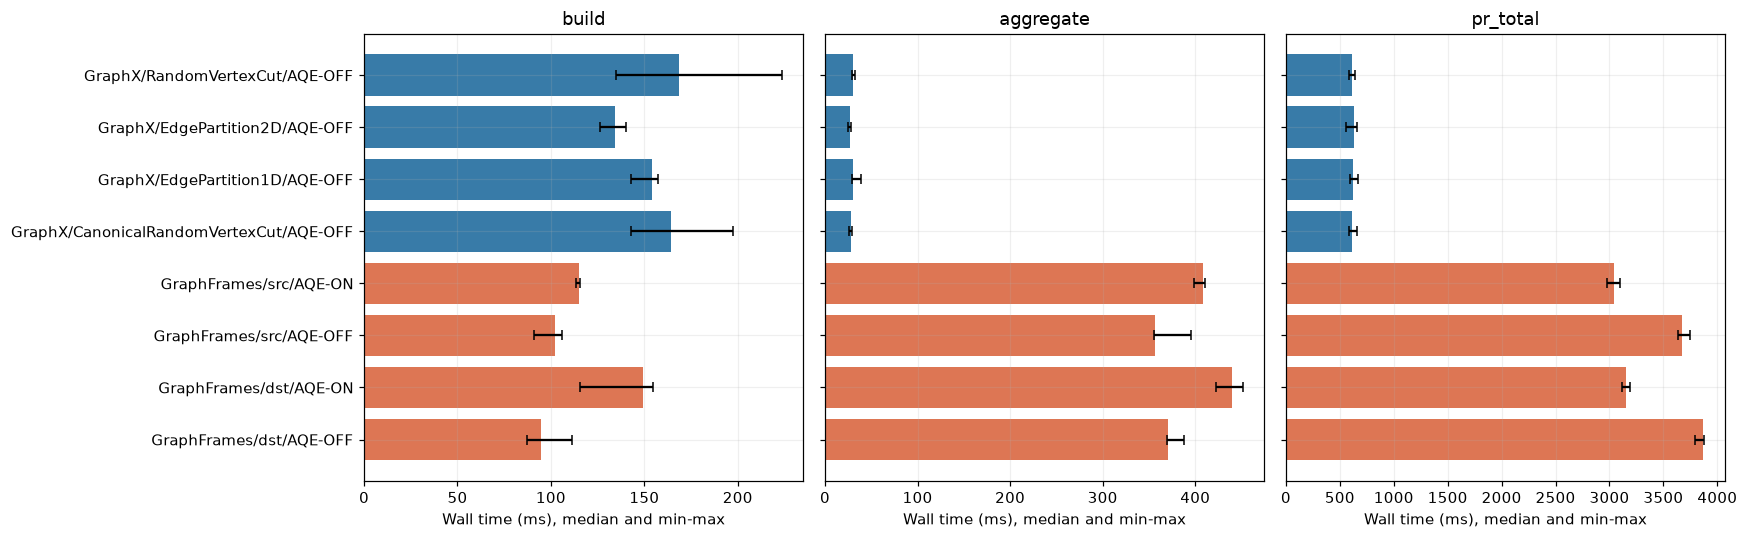

In [4]:
sum_columns = ['wall_ms', 'executor_runtime_ms', 'executor_cpu_ms', 'jvm_gc_ms', 'task_gc_ms', 'shuffle_read_bytes', 'shuffle_write_bytes', 'memory_spill_bytes', 'disk_spill_bytes', 'executor_deserialize_ms', 'result_serialize_ms', 'jobs', 'stages', 'tasks']
pr = measured.loc[measured.phase.isin(['pr_setup', 'pr_iteration'])].groupby(['run','config'])[sum_columns].sum().reset_index()
pr['peak_task_execution_memory_bytes'] = measured.loc[measured.phase.isin(['pr_setup','pr_iteration'])].groupby(['run','config']).peak_task_execution_memory_bytes.max().to_numpy()
pr['phase'] = 'pr_total'
phase_table = pd.concat([measured, pr], ignore_index=True)
summary = phase_table.groupby(['config','phase']).agg(
    wall_median_ms=('wall_ms','median'), wall_min_ms=('wall_ms','min'), wall_max_ms=('wall_ms','max'),
    cpu_median_ms=('executor_cpu_ms','median'), executor_runtime_median_ms=('executor_runtime_ms','median'), jvm_gc_median_ms=('jvm_gc_ms','median'),
    deserialize_median_ms=('executor_deserialize_ms','median'), result_serialize_median_ms=('result_serialize_ms','median'),
    shuffle_read_mib=('shuffle_read_bytes',lambda s: s.median()/2**20),
    shuffle_write_mib=('shuffle_write_bytes',lambda s: s.median()/2**20),
    disk_spill_mib=('disk_spill_bytes',lambda s: s.median()/2**20),
    memory_spill_mib=('memory_spill_bytes',lambda s: s.median()/2**20),
    peak_task_execution_memory_mib=('peak_task_execution_memory_bytes',lambda s: s.median()/2**20),
    jobs_median=('jobs','median'), stages_median=('stages','median'), tasks_median=('tasks','median'))
summary.to_csv(REPORT / 'summary.csv')
display(summary.loc[pd.IndexSlice[:, ['build','aggregate','pr_total']], :])

def save_plot(name):
    plt.tight_layout()
    plt.savefig(REPORT / f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()
    plt.close()

configs = sorted(measured.config.unique())
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, phase in zip(axes, ['build', 'aggregate', 'pr_total']):
    table = summary.xs(phase, level='phase').reindex(configs)
    med = table.wall_median_ms
    ax.barh(configs, med, color=['#387ba8' if c.startswith('GraphX/') else '#dd7654' for c in configs])
    ax.errorbar(med, np.arange(len(configs)), xerr=[med-table.wall_min_ms, table.wall_max_ms-med], fmt='none', ecolor='black', capsize=3)
    ax.set(title=phase, xlabel='Wall time (ms), median and min-max')
save_plot('runtime_comparison')

### Memory và GC: representation có đổi chi phí lưu trữ không?

Cache delta ở cuối build bao gồm các block nội bộ graph cần materialize, không chỉ payload logic của vertices/edges.
GC được đo tự nhiên trong cùng JVM, nên không coi một run có GC=0 là bằng chứng framework không tạo allocation.
Muốn đo peak RSS/heap và allocation rate trên cluster cần thêm profiler hoặc executor process metrics.

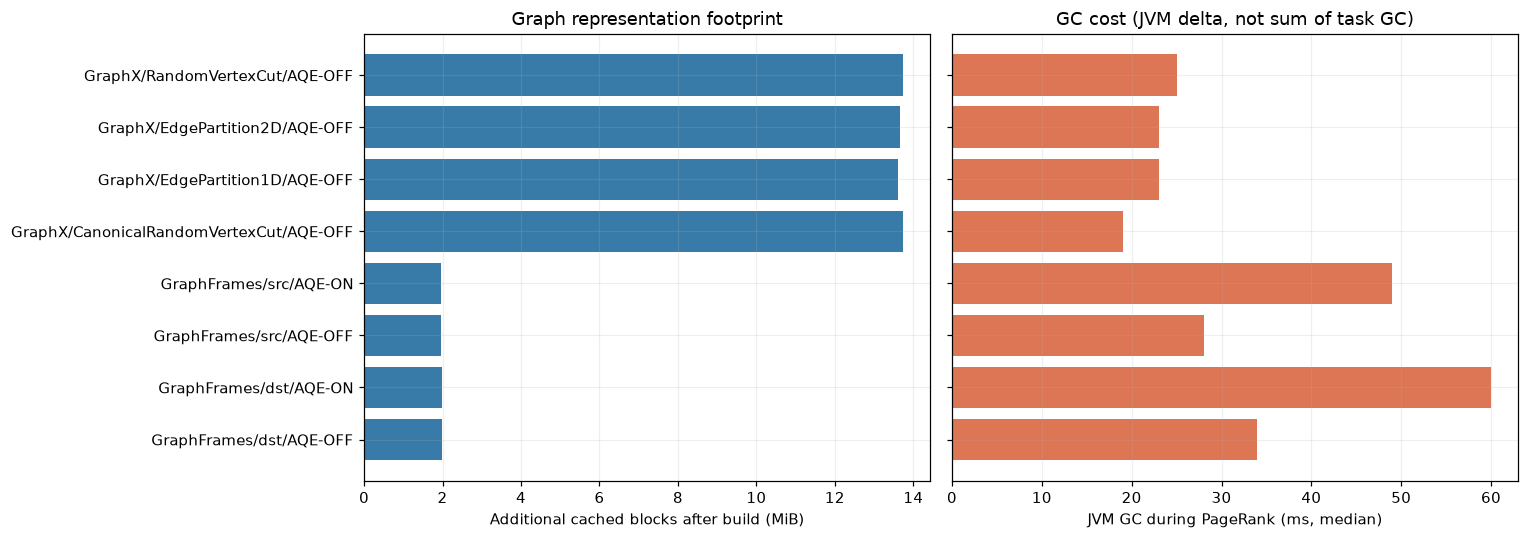

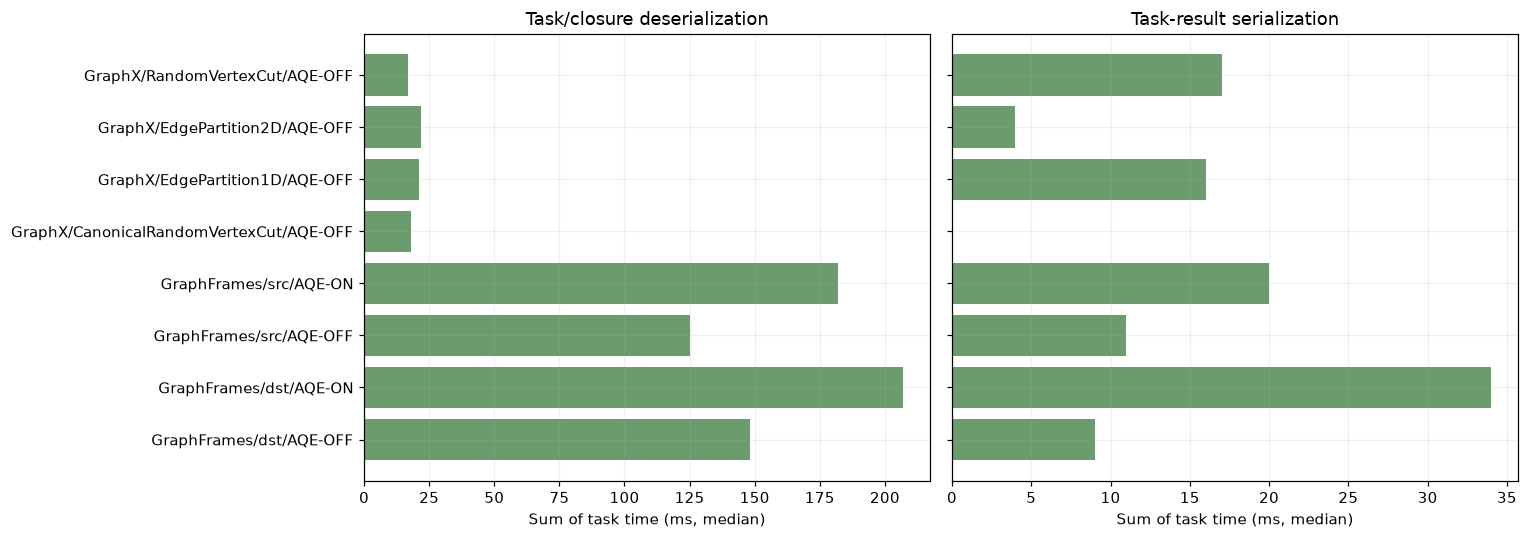

In [5]:
build = measured.loc[measured.phase.eq('build')].groupby('config').cache_delta_bytes.median().reindex(configs) / 2**20
pr_gc = pr.groupby('config').jvm_gc_ms.median().reindex(configs)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
axes[0].barh(configs, build, color='#387ba8')
axes[0].set(xlabel='Additional cached blocks after build (MiB)', title='Graph representation footprint')
axes[1].barh(configs, pr_gc, color='#dd7654')
axes[1].set(xlabel='JVM GC during PageRank (ms, median)', title='GC cost (JVM delta, not sum of task GC)')
save_plot('memory_gc')

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, metric, title in zip(axes, ['deserialize_median_ms','result_serialize_median_ms'], ['Task/closure deserialization','Task-result serialization']):
    values = summary.xs('pr_total', level='phase').reindex(configs)[metric]
    ax.barh(configs, values, color='#6a9c6d')
    ax.set(xlabel='Sum of task time (ms, median)', title=title)
save_plot('task_serialization_metrics')

### Serialize/deserialize payload: microbenchmark có kiểm soát

Cùng 256 cạnh, cùng thứ tự, cùng Kryo serializer và cùng số round-trip trên driver.
So payload `Array[Edge[Double]]` với `Array[InternalRow]` từ Spark SQL, sau warmup và qua 5 repeat.
Đây là chi phí serialize payload cụ thể, không phải serialization toàn EdgePartition, columnar cache hoặc toàn pipeline shuffle.
Không gộp kết quả microbenchmark này với task deserialize/result serialize trong biểu đồ phía trên.


,bytes_per_record,serialize_us_per_record,deserialize_us_per_record,gc_ms
representation,,,,
GraphX Edge[Double] array,28.277,0.122,0.247,0.000
Spark SQL InternalRow array,43.020,0.083,0.103,0.000


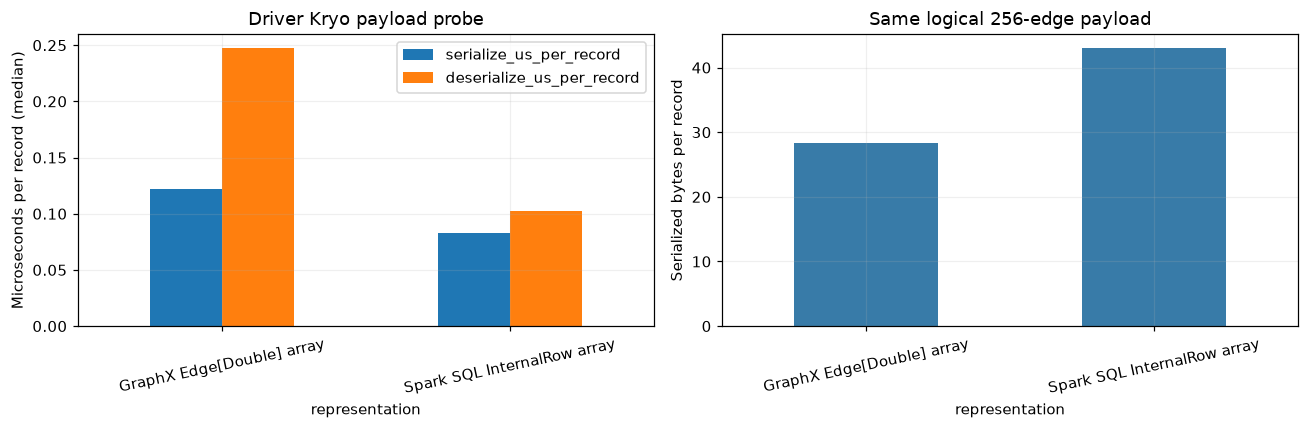

In [6]:
probe = pd.read_csv(RUN_DIR / 'serialization_probe.csv')
probe['serialize_us_per_record'] = probe.serialize_ms * 1000 / (probe.records * probe.loops)
probe['deserialize_us_per_record'] = probe.deserialize_ms * 1000 / (probe.records * probe.loops)
probe['bytes_per_record'] = probe.payload_bytes / probe.records
probe.to_csv(REPORT / 'serialization_probe.csv', index=False)
probe_summary = probe.groupby('representation')[['bytes_per_record','serialize_us_per_record','deserialize_us_per_record','gc_ms']].median()
display(probe_summary)
fig, axes = plt.subplots(1, 2, figsize=(12,4))
probe_summary[['serialize_us_per_record','deserialize_us_per_record']].plot.bar(ax=axes[0], rot=12)
axes[0].set(ylabel='Microseconds per record (median)', title='Driver Kryo payload probe')
probe_summary.bytes_per_record.plot.bar(ax=axes[1],rot=12,color='#387ba8')
axes[1].set(ylabel='Serialized bytes per record', title='Same logical 256-edge payload')
save_plot('payload_serialization')

### Shuffle, spill và task skew: partition có làm công việc cân bằng hơn không?

Repartition theo src có thể gom các hub gửi tiền vào một partition; theo dst có thể gom các hub nhận tiền.
GraphX EdgePartition2D và RandomVertexCut có mục tiêu phân phối khác, nên số cạnh đều chưa đủ kết luận chi phí replication đều.
Đọc cả edge load lẫn thời gian task theo stage.
Nếu spill bằng 0, thí nghiệm này chưa tạo áp lực đủ để kết luận cách hai framework xử lý thiếu bộ nhớ.
Edge-load heatmap giống nhau giữa AQE ON/OFF ở cùng key là điều có thể xảy ra: explicit repartition được giữ, còn AQE tác động các SQL exchange/join về sau.


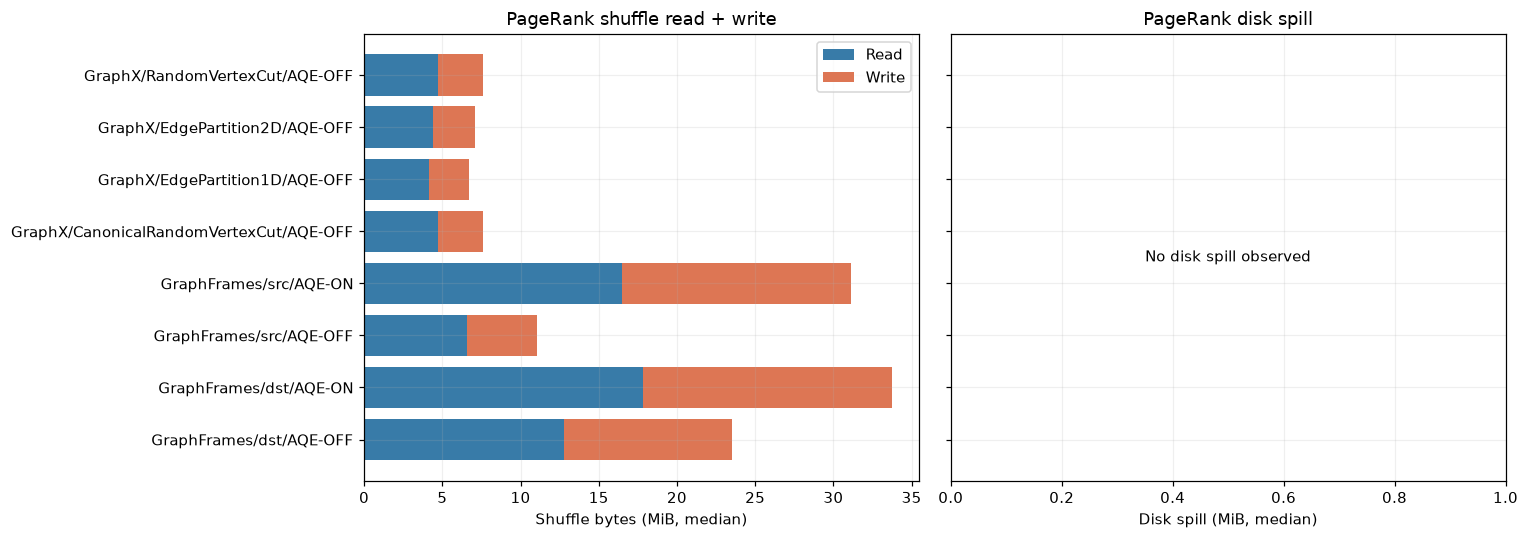

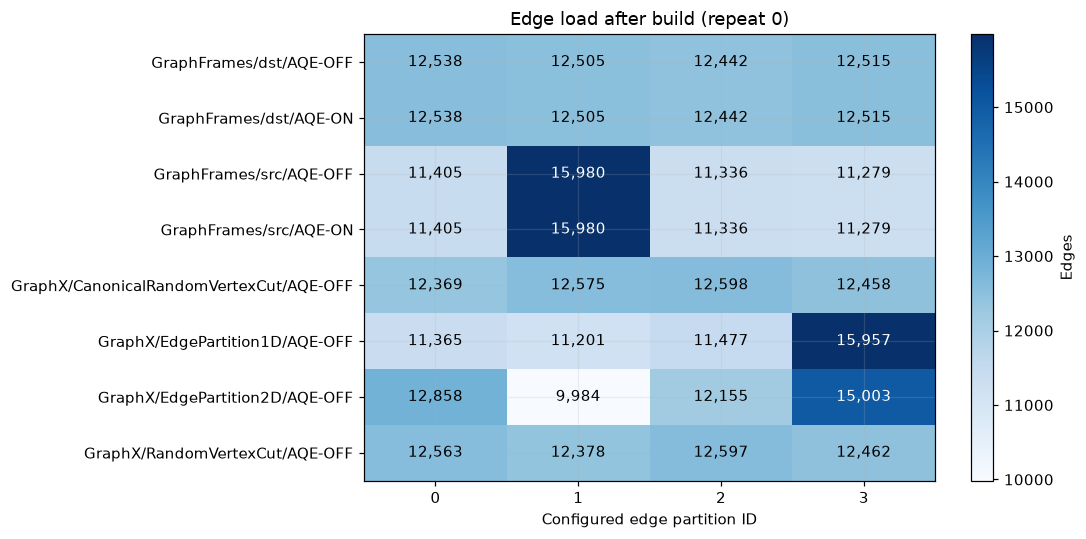

,mean,max,min,std,max_over_mean,coefficient_of_variation
config,,,,,,
GraphFrames/dst/AQE-OFF,"12,500.000","12,538.000","12,442.000",41.061,1.003,0.003
GraphFrames/dst/AQE-ON,"12,500.000","12,538.000","12,442.000",41.061,1.003,0.003
GraphFrames/src/AQE-OFF,"12,500.000","15,980.000","11,279.000","2,320.572",1.278,0.186
GraphFrames/src/AQE-ON,"12,500.000","15,980.000","11,279.000","2,320.572",1.278,0.186
GraphX/CanonicalRandomVertexCut/AQE-OFF,"12,500.000","12,598.000","12,369.000",106.699,1.008,0.009
GraphX/EdgePartition1D/AQE-OFF,"12,500.000","15,957.000","11,201.000","2,307.452",1.277,0.185
GraphX/EdgePartition2D/AQE-OFF,"12,500.000","15,003.000","9,984.000","2,069.014",1.200,0.166
GraphX/RandomVertexCut/AQE-OFF,"12,500.000","12,597.000","12,378.000",99.509,1.008,0.008


,run,phase,iteration,stage_id,tasks,median_ms,max_ms,max_over_median
194,GraphFrames_dst_aqefalse_r1,pr_iteration,3,4604,4,3.000,7,2.333
724,GraphFrames_dst_aqetrue_r2,pr_iteration,4,6512,4,4.500,9,2.000
1189,GraphFrames_src_aqetrue_r0,pr_iteration,4,3167,4,4.500,9,2.000
1327,GraphFrames_src_aqetrue_r1,pr_setup,0,4167,4,1.500,3,2.000
1661,GraphX_EdgePartition1D_aqefalse_r0,pr_iteration,1,2202,4,6.500,13,2.000
1994,GraphX_RandomVertexCut_aqefalse_r0,build,0,1990,4,1.500,3,2.000
1190,GraphFrames_src_aqetrue_r0,pr_iteration,4,3168,4,5.000,9,1.800
1427,GraphFrames_src_aqetrue_r2,pr_iteration,5,5786,4,5.000,9,1.800
845,GraphFrames_src_aqefalse_r0,pr_iteration,2,1945,4,17.500,31,1.771
740,GraphFrames_dst_aqetrue_r2,pr_iteration,5,6583,4,6.000,10,1.667


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
pr_summary = summary.xs('pr_total', level='phase').reindex(configs)
axes[0].barh(configs, pr_summary.shuffle_read_mib, label='Read', color='#387ba8')
axes[0].barh(configs, pr_summary.shuffle_write_mib, left=pr_summary.shuffle_read_mib, label='Write', color='#dd7654')
axes[0].set(xlabel='Shuffle bytes (MiB, median)', title='PageRank shuffle read + write')
axes[0].legend()
axes[1].barh(configs, pr_summary.disk_spill_mib, color='#6a9c6d')
axes[1].set(xlabel='Disk spill (MiB, median)', title='PageRank disk spill')
axes[1].set_xlim(0, max(1, pr_summary.disk_spill_mib.max()*1.1))
if pr_summary.disk_spill_mib.eq(0).all():
    axes[1].text(.5,.5,'No disk spill observed',ha='center',va='center',transform=axes[1].transAxes)
save_plot('shuffle_spill')

load = pd.read_csv(RUN_DIR / 'partition_load.csv').merge(schedule, on='run', validate='many_to_one')
load = load.loc[(~load.warmup) & load['repeat'].eq(0)].copy()
load['config'] = load.framework + '/' + load.strategy + load.aqe.map({False:'/AQE-OFF',True:'/AQE-ON'})
matrix = load.pivot(index='config', columns='partition_id', values='edges').reindex(configs).fillna(0)
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(matrix, aspect='auto', cmap='Blues')
ax.set_yticks(range(len(matrix)), matrix.index)
ax.set_xticks(range(len(matrix.columns)), matrix.columns)
ax.set(xlabel='Configured edge partition ID', title='Edge load after build (repeat 0)')
for i in range(len(matrix)):
    for j in range(len(matrix.columns)):
        ax.text(j, i, f'{matrix.iloc[i,j]:,.0f}', ha='center', va='center', color='white' if im.norm(matrix.iloc[i,j]) > .55 else 'black')
fig.colorbar(im, ax=ax, label='Edges')
save_plot('partition_load')
load_stats = matrix.agg(['mean','max','min','std'], axis=1)
load_stats['max_over_mean'] = load_stats['max'] / load_stats['mean']
load_stats['coefficient_of_variation'] = load_stats['std'] / load_stats['mean']
display(load_stats)
worst = stage_skew.loc[(~stage_skew.warmup) & stage_skew.tasks.ge(2)].nlargest(12, 'max_over_median')
display(worst[['run','phase','iteration','stage_id','tasks','median_ms','max_ms','max_over_median']])

### Runtime từng vòng: graph state và SQL execution khác nhau ra sao?

Vòng đầu có thể xây routing/replicated view hoặc làm nóng code path mới, nên đọc cả hình dạng đường cong và độ biến thiên giữa repeat.
Cùng số iteration không có nghĩa cùng số job/stage; các operator nội bộ và checkpoint quyết định phần còn lại.
Checkpoint có thể làm GraphX phải so sánh các vertex partition có index identity khác nhau.
Cảnh báo `Diffing two VertexPartitions with different indexes is slow` trong log được báo trong phần giới hạn; không diễn giải tốc độ ở đây như tốc độ của một implementation không checkpoint.


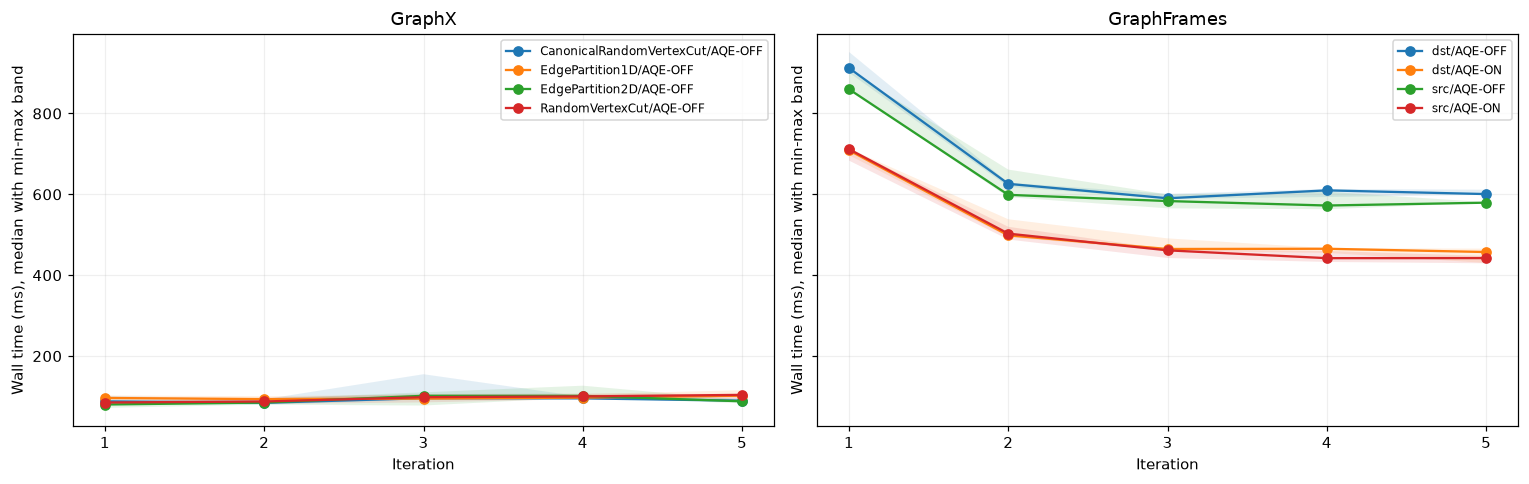

In [8]:
iteration_table = measured.loc[measured.phase.eq('pr_iteration')].groupby(['config','iteration']).wall_ms.agg(median='median', minimum='min', maximum='max').reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, framework in zip(axes, ['GraphX','GraphFrames']):
    for config, table in iteration_table.loc[iteration_table.config.str.startswith(framework+'/')].groupby('config'):
        ax.plot(table.iteration, table['median'], marker='o', label=config.split('/',1)[1])
        ax.fill_between(table.iteration, table.minimum, table.maximum, alpha=.12)
    ax.set(title=framework, xlabel='Iteration', ylabel='Wall time (ms), median with min-max band')
    ax.set_xticks(range(1, ITERATIONS+1))
    ax.legend(fontsize=8)
save_plot('runtime_per_iteration')

## 4. DAG, Spark UI và execution plan: bằng chứng để giải thích WHY

RDD lineage được lưu cho GraphX; SQL logical/physical plan được lưu cho GraphFrames ở repeat 0.
Các SQL execution start và adaptive update từ event log được giữ trong `sql_plans.json`, tránh chỉ dựa vào plan trước action.
Một plan của DataFrame đã cache có thể chỉ hiện InMemoryTableScan; cần đọc plan tạo cache và SQL execution gốc để thấy join/exchange thực tế.
HTML UI snapshot là bản ghi page trong warmup, không phải screenshot browser; event log có toàn bộ benchmark để History Server dựng lại UI.
Đồ thị stage bên dưới dùng parent IDs từ event log, không phải một sơ đồ kiến trúc minh họa.

,run,sql_execution_starts,adaptive_updates,SortMergeJoin_mentions,Exchange_mentions,HashAggregate_mentions,InMemoryTableScan_mentions
0,GraphFrames_src_aqefalse_r0,24,0,76,124,140,172
1,GraphFrames_dst_aqetrue_r0,29,83,1006,2702,1260,2133
2,GraphFrames_src_aqetrue_r0,29,82,1002,2557,1260,2120
3,GraphFrames_dst_aqefalse_r0,24,0,76,154,140,172


Operator mentions là số lần xuất hiện trong các plan snapshots, không phải số operator thực thi duy nhất.

GraphX evidence: GraphX_EdgePartition2D_aqefalse_r0_rdd_dag.txt
(2) VertexRDDImpl[3960] at RDD at VertexRDD.scala:57 []
 |  VertexRDD ZippedPartitionsRDD2[3959] at zipPartitions at VertexRDDImpl.scala:226 []
 |      CachedPartitions: 2; MemorySize: 2.5 MiB; DiskSize: 0.0 B
 |  VertexRDD, VertexRDD ZippedPartitionsRDD2[3947] at zipPartitions at VertexRDD.scala:322 []
 |      CachedPartitions: 2; MemorySize: 2.5 MiB; DiskSize: 0.0 B
 |  ShuffledRDD[3943] at partitionBy at VertexRDD.scala:319 []
 +-(2) MapPartitionsRDD[3932] at map at cmd10.sc:9 []
    |  MapPartitionsRDD[3931] at rdd at cmd10.sc:8 []
    |  SQLExecutionRDD[3930] at rdd at cmd10.sc:8 []
    |  MapPartitionsRDD[3929] at rdd at cmd10.sc:8 []
    |  MapPartitionsRDD[3928] at rdd at cmd10.sc:8 []
    |  MapPartitionsRDD[3927] at rdd at cmd10.sc:8 []
    |  MapPartitionsRDD[3926] at rdd at cmd10.sc:8 []
    |  *(1) Column

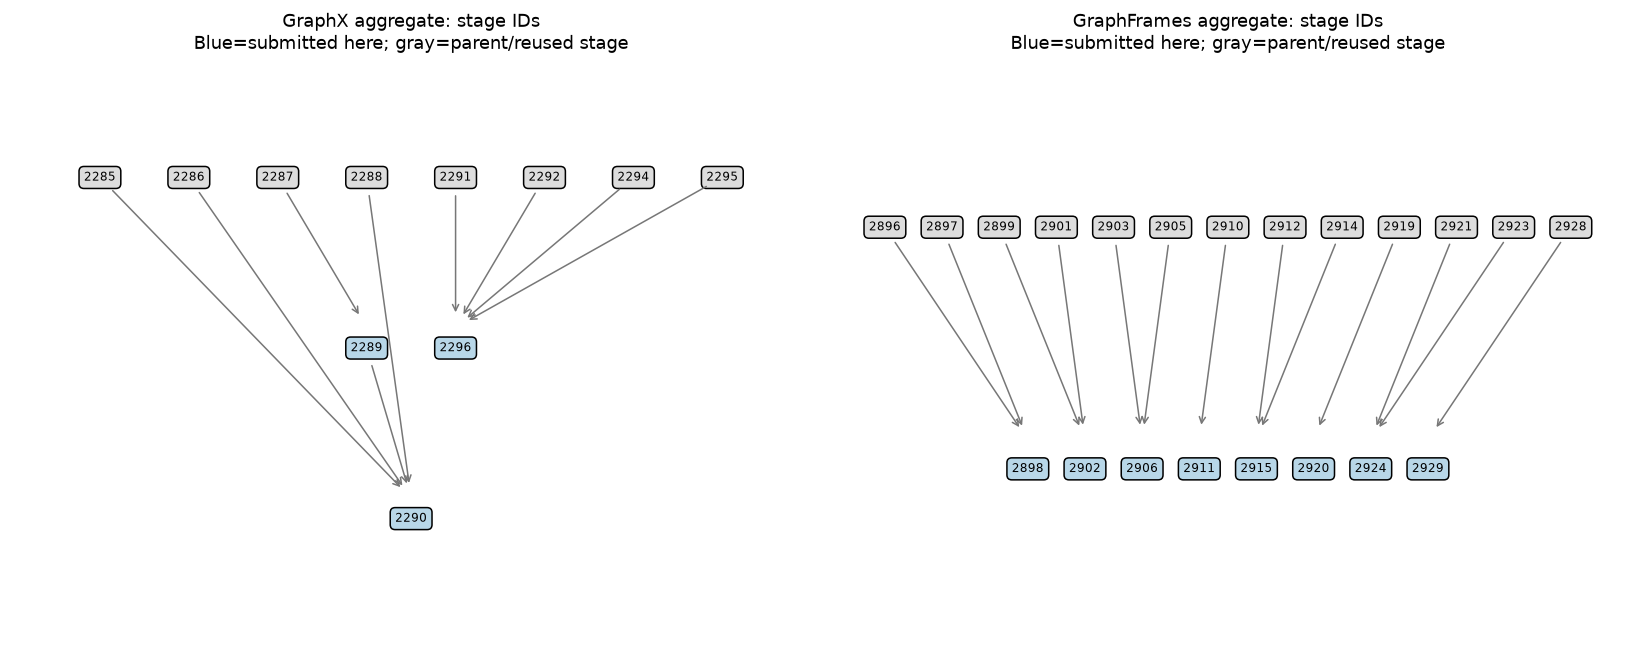

UI snapshots: ['GraphFrames_SQL.html', 'GraphFrames_jobs.html', 'GraphFrames_stages.html', 'GraphFrames_storage.html', 'GraphX_SQL.html', 'GraphX_jobs.html', 'GraphX_stages.html', 'GraphX_storage.html']
Replay bằng History Server, sử dụng event log directory: /home/tuanta/graphX/reports/architecture/runs/scala_1792035232036/events
History Server: đặt spark.history.fs.logDirectory thành file:///home/tuanta/graphX/reports/architecture/runs/scala_1792035232036/events


In [9]:
plan_rows = []
for run in schedule.loc[schedule['repeat'].eq(0) & schedule.framework.eq('GraphFrames'), 'run']:
    evidence = [r for r in sql_events if r['group'].startswith(run+'|')]
    text = '\n'.join(r['plan'] for r in evidence)
    plan_rows.append({'run':run, 'sql_execution_starts':sum(r['event']=='SparkListenerSQLExecutionStart' for r in evidence),
                      'adaptive_updates':sum(r['event']=='SparkListenerSQLAdaptiveExecutionUpdate' for r in evidence),
                      'SortMergeJoin_mentions':text.count('SortMergeJoin'), 'Exchange_mentions':text.count('Exchange'),
                      'HashAggregate_mentions':text.count('HashAggregate'), 'InMemoryTableScan_mentions':text.count('InMemoryTableScan')})
plan_comparison = pd.DataFrame(plan_rows)
plan_comparison.to_csv(REPORT / 'plan_comparison.csv',index=False)
display(plan_comparison)
print('Operator mentions là số lần xuất hiện trong các plan snapshots, không phải số operator thực thi duy nhất.')

for framework, strategy, aqe in [('GraphX','EdgePartition2D',False), ('GraphFrames','src',True)]:
    run = schedule.loc[(schedule['repeat']==0) & schedule.framework.eq(framework) & schedule.strategy.eq(strategy) & schedule.aqe.eq(aqe), 'run'].iloc[0]
    name = run + ('_rdd_dag.txt' if framework=='GraphX' else '_pr_logical_plan.txt')
    text = (RUN_DIR / name).read_text()
    print('\n'+framework+' evidence: '+name)
    print('\n'.join(text.splitlines()[:45]))

# DAG của các stage thực sự được submit trong aggregate, cộng node cha dùng lại.
fig, axes = plt.subplots(1,2,figsize=(15,6))
all_parents = {int(r.stage_id): list(r.parents) for r in stages.itertuples()}
for ax, framework, strategy, aqe in zip(axes,['GraphX','GraphFrames'],['EdgePartition2D','src'],[False,True]):
    run = schedule.loc[schedule['repeat'].eq(0) & schedule.framework.eq(framework) & schedule.strategy.eq(strategy) & schedule.aqe.eq(aqe),'run'].iloc[0]
    selected = stages.loc[stages.run.eq(run) & stages.phase.eq('aggregate')]
    live = set(selected.stage_id)
    nodes = live | {parent for stage in live for parent in all_parents.get(stage,[])}
    depth = {}
    def layer(stage):
        if stage not in depth:
            depth[stage] = 1 + max([layer(parent) for parent in all_parents.get(stage,[]) if parent in nodes] or [-1])
        return depth[stage]
    positions={}
    for level in sorted({layer(node) for node in nodes}):
        row=sorted(node for node in nodes if depth[node]==level)
        for i,node in enumerate(row): positions[node]=(i-(len(row)-1)/2, -level)
    for node,(x,y) in positions.items():
        ax.text(x,y,str(node),ha='center',va='center',fontsize=8,bbox=dict(boxstyle='round,pad=.4',facecolor='#b8d7e8' if node in live else '#dddddd'))
        for parent in all_parents.get(node,[]):
            if parent in positions: ax.annotate('',xy=(x,y+.12),xytext=positions[parent],arrowprops=dict(arrowstyle='->',color='#777777',shrinkA=12,shrinkB=10))
    if positions:
        xs,ys=zip(*positions.values()); ax.set_xlim(min(xs)-1,max(xs)+1); ax.set_ylim(min(ys)-.7,max(ys)+.7)
    ax.set_title(framework+' aggregate: stage IDs\nBlue=submitted here; gray=parent/reused stage')
    ax.axis('off')
save_plot('stage_dag_comparison')

ui_files = sorted((RUN_DIR/'ui').glob('*')) if (RUN_DIR/'ui').exists() else []
print('UI snapshots:', [p.name for p in ui_files])
print('Replay bằng History Server, sử dụng event log directory:', EVENT_DIR)
print('History Server: đặt spark.history.fs.logDirectory thành',EVENT_DIR.as_uri())

## 5. Kết luận: nối quan sát với cơ chế, không chỉ chọn người thắng

Ô sau tạo kết luận trực tiếp từ kết quả thực nghiệm.
Tách rõ dữ kiện đo được, lời giải thích phù hợp với plan, và những phần chưa được chứng minh.
Các kết quả local không đủ để khẳng định ưu thế trên mọi cluster, quy mô graph hoặc cấu hình broadcast.

In [10]:
pr_stats = summary.xs('pr_total', level='phase')
gx = pr_stats.loc[pr_stats.index.str.startswith('GraphX/')].sort_values('wall_median_ms')
gf = pr_stats.loc[pr_stats.index.str.startswith('GraphFrames/')].sort_values('wall_median_ms')
best_gx, best_gf = gx.iloc[0], gf.iloc[0]
ratio = best_gf.wall_median_ms / best_gx.wall_median_ms
build_summary = measured.loc[measured.phase.eq('build')].groupby('framework').cache_delta_bytes.median()/2**20
spill = measured.disk_spill_bytes.sum()
notes = [
    f'Input thực nghiệm gồm **{manifest["vertices"]:,} vertex và {manifest["edges"]:,} cạnh**, {REPEATS} repeat sau {WARMUPS} warmup; **{MASTER}**, {PARTITIONS} edge/shuffle partitions, {ITERATIONS} iteration.',
    f'Custom PageRank nhanh nhất của GraphX: **{gx.index[0]}**, median **{best_gx.wall_median_ms:,.1f} ms**; của GraphFrames: **{gf.index[0]}**, median **{best_gf.wall_median_ms:,.1f} ms**. Tỷ số GraphFrames/GraphX là **{ratio:.2f}** trên input và protocol này.',
    f'Các cấu hình tốt nhất có median PageRank shuffle read/write **{best_gx.shuffle_read_mib:.2f}/{best_gx.shuffle_write_mib:.2f} MiB** cho GraphX và **{best_gf.shuffle_read_mib:.2f}/{best_gf.shuffle_write_mib:.2f} MiB** cho GraphFrames.',
    f'Graph build tăng median cache **{build_summary["GraphX"]:.2f} MiB** cho GraphX và **{build_summary["GraphFrames"]:.2f} MiB** cho GraphFrames. Đây là footprint các Spark cached block ở build, không phải peak RSS.',
    'Cùng kết quả số học nhưng runtime, stage/task và shuffle khác nhau: các join/aggregate trong SQL plan và routing/index trong GraphX là bằng chứng cấu trúc để giải thích khác biệt; một metric riêng lẻ chưa chứng minh quan hệ nhân quả.',
]
for key in ['src','dst']:
    off=pr_stats.loc[f'GraphFrames/{key}/AQE-OFF']; on=pr_stats.loc[f'GraphFrames/{key}/AQE-ON']
    notes.append(f'GraphFrames repartition **{key}**: AQE ON/OFF runtime ratio **{on.wall_median_ms/off.wall_median_ms:.2f}**, median số task **{on.tasks_median:.0f}/{off.tasks_median:.0f}**. Đọc adaptive updates và task count để xem AQE đã thực sự đổi execution hay chưa.')
notes.append('**Không có disk spill** trong các pha được đo; chưa đủ bằng chứng so sánh khả năng chịu áp lực bộ nhớ.' if spill==0 else f'Tổng disk spill trong các pha đo là **{spill/2**20:.2f} MiB**; cần đối chiếu stage và config gây spill.')
log_text = (RUN_DIR/'spark.log').read_text(errors='replace') if (RUN_DIR/'spark.log').exists() else ''
index_warnings = log_text.count('Diffing two VertexPartitions with different indexes is slow')
notes.append('Durable checkpoint được giữ trong timing và có thể ảnh hưởng index identity của GraphX; benchmark này chưa tách riêng lợi ích của việc giảm tần suất checkpoint.')
text='\n\n'.join(note.replace('. ', '.\n') for note in notes)
display(Markdown(text))
(REPORT/'findings.md').write_text(text+'\n')

Input thực nghiệm gồm **54,019 vertex và 50,000 cạnh**, 3 repeat sau 1 warmup; **local[2]**, 4 edge/shuffle partitions, 5 iteration.

Custom PageRank nhanh nhất của GraphX: **GraphX/RandomVertexCut/AQE-OFF**, median **609.2 ms**; của GraphFrames: **GraphFrames/src/AQE-ON**, median **3,043.5 ms**.
Tỷ số GraphFrames/GraphX là **5.00** trên input và protocol này.

Các cấu hình tốt nhất có median PageRank shuffle read/write **4.73/2.86 MiB** cho GraphX và **16.51/14.63 MiB** cho GraphFrames.

Graph build tăng median cache **13.70 MiB** cho GraphX và **1.97 MiB** cho GraphFrames.
Đây là footprint các Spark cached block ở build, không phải peak RSS.

Cùng kết quả số học nhưng runtime, stage/task và shuffle khác nhau: các join/aggregate trong SQL plan và routing/index trong GraphX là bằng chứng cấu trúc để giải thích khác biệt; một metric riêng lẻ chưa chứng minh quan hệ nhân quả.

GraphFrames repartition **src**: AQE ON/OFF runtime ratio **0.83**, median số task **277/155**.
Đọc adaptive updates và task count để xem AQE đã thực sự đổi execution hay chưa.

GraphFrames repartition **dst**: AQE ON/OFF runtime ratio **0.82**, median số task **286/207**.
Đọc adaptive updates và task count để xem AQE đã thực sự đổi execution hay chưa.

**Không có disk spill** trong các pha được đo; chưa đủ bằng chứng so sánh khả năng chịu áp lực bộ nhớ.

Durable checkpoint được giữ trong timing và có thể ảnh hưởng index identity của GraphX; benchmark này chưa tách riêng lợi ích của việc giảm tần suất checkpoint.

1509

### Bảng WHY: quan sát nào ủng hộ lời giải thích nào?

Đặt metric cạnh dấu vết implementation để tránh kết luận chỉ từ một biểu đồ runtime.
Các lời giải thích là diễn giải của input và execution plan đã đo, chưa phải kết luận nhân quả cho mọi quy mô.


In [11]:
src_load = load_stats.loc['GraphFrames/src/AQE-OFF', 'max_over_mean']
dst_load = load_stats.loc['GraphFrames/dst/AQE-OFF', 'max_over_mean']
why_table = pd.DataFrame([
    ('Khởi tạo và lưu graph',
     f'GraphX cache +{build_summary["GraphX"]:.2f} MiB; GraphFrames +{build_summary["GraphFrames"]:.2f} MiB',
     'GraphX dựng thêm edge partitions, vertex index và routing; GraphFrames cache dữ liệu có schema qua Spark SQL.',
     'Cache nhỏ hơn chưa dự đoán được iteration nhanh hơn; hai dạng storage có overhead khác nhau.'),
    ('PageRank và message passing',
     f'Best GraphFrames/GraphX runtime ratio={ratio:.2f}; shuffle read {best_gf.shuffle_read_mib:.2f}/{best_gx.shuffle_read_mib:.2f} MiB',
     'GraphFrames plan có triplet joins, message aggregation và state join; GraphX dùng Graph[Double, Double], EdgeContext và TripletFields.Src.',
     'Đây là các code path thực tế, cùng checkpoint policy; không tách riêng CPU planning hay network latency.'),
    ('Repartition src so với dst',
     f'Max/mean edge load: src={src_load:.3f}, dst={dst_load:.3f}',
     'Hash cùng sender giữ các cạnh của sender đó cùng partition; hash receiver phân phối khác trên graph này.',
     'Cạnh cân bằng không có nghĩa task, vertex replication hoặc bytes cũng cân bằng.'),
    ('AQE',
     f'{int(plan_comparison.adaptive_updates.sum())} adaptive plan updates trong các run GraphFrames repeat 0',
     'AQE thay SQL query stages theo statistics thực tế; tác động được thấy ở plan, số task, shuffle và runtime.',
     'Trong run này AQE ON có thể nhanh hơn dù nhiều task/shuffle hơn; không giả định AQE luôn giảm mọi metric.'),
    ('Payload serialize/deserialize',
     f'Kryo driver probe: Edge array {probe_summary.iloc[0].bytes_per_record:.1f} bytes/record; InternalRow array {probe_summary.iloc[1].bytes_per_record:.1f}',
     'Representation ảnh hưởng kích thước và chi phí round-trip; kết quả của probe khác với tốc độ toàn pipeline.',
     'Probe không bao gồm EdgePartition, columnar cache hay network; không dùng nó thay shuffle/task metrics.'),
], columns=['Góc nhìn','Dữ kiện đo được','WHY phù hợp với dấu vết','Giới hạn diễn giải'])
why_table.to_csv(REPORT / 'why_comparison.csv', index=False)
display(HTML('<style>.why-table td {white-space:normal; text-align:left; vertical-align:top;}</style>' + why_table.to_html(index=False, classes='why-table')))

Góc nhìn,Dữ kiện đo được,WHY phù hợp với dấu vết,Giới hạn diễn giải
Khởi tạo và lưu graph,GraphX cache +13.70 MiB; GraphFrames +1.97 MiB,"GraphX dựng thêm edge partitions, vertex index và routing; GraphFrames cache dữ liệu có schema qua Spark SQL.",Cache nhỏ hơn chưa dự đoán được iteration nhanh hơn; hai dạng storage có overhead khác nhau.
PageRank và message passing,Best GraphFrames/GraphX runtime ratio=5.00; shuffle read 16.51/4.73 MiB,"GraphFrames plan có triplet joins, message aggregation và state join; GraphX dùng Graph[Double, Double], EdgeContext và TripletFields.Src.","Đây là các code path thực tế, cùng checkpoint policy; không tách riêng CPU planning hay network latency."
Repartition src so với dst,"Max/mean edge load: src=1.278, dst=1.003",Hash cùng sender giữ các cạnh của sender đó cùng partition; hash receiver phân phối khác trên graph này.,"Cạnh cân bằng không có nghĩa task, vertex replication hoặc bytes cũng cân bằng."
AQE,165 adaptive plan updates trong các run GraphFrames repeat 0,"AQE thay SQL query stages theo statistics thực tế; tác động được thấy ở plan, số task, shuffle và runtime.",Trong run này AQE ON có thể nhanh hơn dù nhiều task/shuffle hơn; không giả định AQE luôn giảm mọi metric.
Payload serialize/deserialize,Kryo driver probe: Edge array 28.3 bytes/record; InternalRow array 43.0,Representation ảnh hưởng kích thước và chi phí round-trip; kết quả của probe khác với tốc độ toàn pipeline.,"Probe không bao gồm EdgePartition, columnar cache hay network; không dùng nó thay shuffle/task metrics."


### Đọc kết quả theo chuỗi nguyên nhân

1. **Representation → cache:** xem class thực tế, cached bytes và GC; không dùng cache footprint thay cho tổng tài nguyên hệ thống.
2. **Partition → load → shuffle:** đối chiếu phân bố cạnh, skew theo stage và shuffle bytes; cạnh đều chưa đảm bảo cân bằng vertex replication.
3. **Engine → plan → jobs/tasks:** xem GraphFrames có join/exchange/aggregate nào, GraphX có lineage/routing nào, và AQE thực sự đổi plan ra sao.
4. **Iteration → state/checkpoint:** so đường runtime từng vòng và kiểm tra checkpoint overhead đã nằm trong timer.
5. **Kết luận → phạm vi:** chỉ khẳng định điều bảng đo hỗ trợ; chưa có cluster network, broadcast ON, peak RSS hoặc profiler allocation thì không kết luận thay cho chúng.

Để mở rộng thí nghiệm, thay sample size, số partition và master, rồi chạy lại cùng protocol.
Không trộn kết quả hai input hoặc hai môi trường vào một bảng so sánh mà không ghi rõ khác biệt.
Toàn bộ mã benchmark và các biểu đồ đã lưu output trong notebook này; raw event log và plan được giữ ở reports để audit.